In [30]:
import math
import random
import json
from copy import deepcopy

from shapely.geometry import Polygon, box
from shapely.affinity import translate
from shapely.ops import unary_union

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

import os
import re
import numpy as np

from svgpathtools import svg2paths2
from collections import defaultdict


from shapely.geometry import Polygon as ShapelyPolygon, MultiPolygon, box
from shapely.affinity import translate, rotate
from shapely.ops import unary_union
from shapely.geometry import box
from shapely.affinity import translate

In [42]:
def extract_color(attr):
    """
    Extract fill or stroke color from SVG attributes.
    Supports hex and rgb() styles from CorelDRAW.
    """

    # Direct attributes
    if attr.get("fill") and attr["fill"] != "none":
        return attr["fill"]

    if attr.get("stroke") and attr["stroke"] != "none":
        return attr["stroke"]

    style = attr.get("style", "")

    # Hex colors
    m = re.search(r"fill:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    m = re.search(r"stroke:\s*(#[0-9A-Fa-f]{6})", style)
    if m:
        return m.group(1)

    # rgb() colors (Corel)
    m = re.search(r"(fill|stroke):\s*rgb\([^)]+\)", style)
    if m:
        return m.group(0)  # use full rgb(...) string as key

    return None
    
def parse_filename(filename):
    """
    JB_FRONT_16-18-20.svg  → sizes = ['16','18','20']
    JB_FRONT_M-L-XL.svg    → sizes = ['M','L','XL']
    """

    name = os.path.splitext(filename)[0]

    parts = name.split("_")
    if len(parts) < 3:
        raise ValueError(f"Invalid filename format: {filename}")

    brand = parts[0]
    part = parts[1].upper()
    size_list = parts[2]

    sizes = size_list.split("-")

    return part, sizes

def svg_path_to_polygon(path, svg_attr, samples=40):
    # --- Parse viewBox ---
    vb_x, vb_y, vb_w, vb_h = map(float, svg_attr["viewBox"].split())

    # --- Parse physical size in mm ---
    width_mm = float(svg_attr["width"].replace("mm", ""))
    height_mm = float(svg_attr["height"].replace("mm", ""))

    scale_x = width_mm / vb_w
    scale_y = height_mm / vb_h

    raw = []
    for seg in path:
        for t in np.linspace(0, 1, samples):
            pt = seg.point(t)
            raw.append((pt.real, pt.imag))

    # Convert to inches
    pts = []
    for x, y in raw:
        x_mm = (x - vb_x) * scale_x
        y_mm = (y - vb_y) * scale_y
        pts.append((x_mm / 25.4, y_mm / 25.4))

    # Flip Y and normalize
    max_y = max(y for _, y in pts)
    pts = [(x, max_y - y) for x, y in pts]

    min_x = min(x for x, _ in pts)
    min_y = min(y for _, y in pts)
    pts = [(x - min_x, y - min_y) for x, y in pts]

    return pts

def load_svg_file(svg_path):
    paths, attrs, svg_attr = svg2paths2(svg_path)

    colored_groups = defaultdict(list)
    uncolored_paths = []

    for path, attr in zip(paths, attrs):
        color = extract_color(attr)
        if color is None:
            uncolored_paths.append(path)
        else:
            colored_groups[color].append(path)

    polygons = []

    # --- Case 1: color-based grouping ---
    if colored_groups:
        for color, group in colored_groups.items():
            pts = []
            for p in group:
                pts.extend(svg_path_to_polygon(p, svg_attr))

            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)

    # --- Case 2: fallback (no colors) ---
    else:
        for p in paths:
            pts = svg_path_to_polygon(p, svg_attr)
            poly = ShapelyPolygon(pts)

            if poly.area > 1e-3:
                polygons.append(poly)
    
    if not polygons:
        raise ValueError(f"No valid polygons found in {svg_path}")

    return polygons
    
def process_design_folder(folder_path):
    all_shapes = []

    for file in os.listdir(folder_path):
        if not file.lower().endswith(".svg"):
            continue

        part, sizes = parse_filename(file)
        svg_path = os.path.join(folder_path, file)

        polygons = load_svg_file(svg_path)
        
        sized_polys = assign_sizes(polygons, sizes)
        
        for size, poly in sized_polys:
            all_shapes.append({
                "part": part,
                "size": size,
                "polygon": poly
            })
    
    # Save structured output
    out_path = os.path.join(folder_path, "parsed_shapes.json")
    with open(out_path, "w") as f:
        json.dump(all_shapes, f, indent=2)

    return all_shapes            

def assign_sizes(polygons, sizes):
    assert len(polygons) == len(sizes), (
        f"Size count mismatch: {len(polygons)} polygons vs {len(sizes)} sizes"
    )

    areas = [(poly.area, poly) for poly in polygons]
    areas.sort(key=lambda x: x[0])  # smallest → largest
    validate_monotonic_areas(polygons)
    result = []
    for size, (_, poly) in zip(sizes, areas):
        result.append((size, list(poly.exterior.coords)))

    return result

def validate_monotonic_areas(polygons):
    areas = sorted(poly.area for poly in polygons)
    for i in range(len(areas) - 1):
        ratio = areas[i + 1] / areas[i]
        if ratio < 1.02:
            raise ValueError(
                "Two sizes have nearly identical area. "
                "Check colors or duplicate patterns."
            )

def clean(poly):
    """
    Fix invalid polygons.
    Mandatory for stable nesting.
    """
    if not poly.is_valid:
        poly = poly.buffer(0)
    return poly

    
def extract_polygons(shape_items):
    """
    Converts process_design_folder() output
    into pure shapely polygon list.
    """
    polys = []

    for item in shape_items:
        poly = item["polygon"]

        # Already shapely polygon → OK
        if hasattr(poly, "bounds"):
            polys.append(poly)
        else:
            # If stored as point list
            polys.append(Polygon(poly))

    return polys
    
def layout_to_kpi_items(polys):
    """
    Convert shapely polygon list into
    format expected by evaluate_kpis()
    """
    items = []

    for p in polys:
        coords = list(p.exterior.coords)
        items.append({
            "polygon": coords
        })

    return items
    
def evaluate_kpis(placed_shapes, strip_width):
    max_y = 0.0
    used_area = 0.0

    for item in placed_shapes:
        poly = item["polygon"]

        for _, y in poly:
            max_y = max(max_y, y)

        area = 0.0
        n = len(poly)
        for i in range(n):
            x1, y1 = poly[i]
            x2, y2 = poly[(i + 1) % n]
            area += (x1 * y2 - x2 * y1)
        used_area += abs(area) / 2.0

    total_area = strip_width * max_y
    empty_ratio = 1.0 - (used_area / total_area) if total_area > 0 else 0.0

    return {
        "layer_length_in": max_y,
        "used_area_in2": used_area,
        "total_area_in2": total_area,
        "empty_ratio": empty_ratio
    }

def convert_for_kpi(placed_shapes):
    kpi_items = []

    for s in placed_shapes:
        coords = list(s.poly.exterior.coords)
        kpi_items.append({
            "part": s.part,
            "size": s.size,
            "polygon": coords
        })

    return kpi_items


def build_shapes(shape_items):
    shapes = []
    for item in shape_items:
        poly = item["polygon"]
        if not hasattr(poly, "bounds"):
            poly = Polygon(poly)

        shapes.append(
            Shape(item["part"], item["size"], poly)
        )
    return shapes



class Shape:
    def __init__(self, part, size, poly):
        self.part = part
        self.size = size
        self.poly = poly

    def area(self):
        return self.poly.area

    def copy(self):
        return Shape(self.part, self.size,
                     Polygon(self.poly.exterior.coords))

def place_shape(shape, x, y):
    minx, miny, maxx, maxy = shape.poly.bounds
    moved = translate(shape.poly,
                      xoff=x - minx,
                      yoff=y - miny)
    return Shape(shape.part, shape.size, moved)

def intersects_any(test_shape, placed):
    for p in placed:
        if test_shape.poly.intersects(p.poly):
            return True
    return False




In [46]:
def to_poly(p):
    if isinstance(p, Polygon):
        return p
    return Polygon(p)

def collides(test_poly, placed):
    for p in placed:
        if test_poly.intersects(p) and not test_poly.touches(p):
            return True
    return False


def drop_down(poly, placed, step=0.25, max_iter=500):
    for _ in range(max_iter):
        moved = translate(poly, yoff=-step)

        if moved.bounds[1] < 0:
            return poly

        if collides(moved, placed):
            return poly

        poly = moved

    return poly

def drop_full(poly, placed, step=0.25):
    while True:
        moved = translate(poly, yoff=-step)

        if moved.bounds[1] < 0:
            return poly

        if collides(moved, placed):
            return poly

        poly = moved


def slide_to_wall(poly, direction, strip_width, step=0.25):

    while True:
        moved = translate(poly, xoff=direction * step)
        minx, _, maxx, _ = moved.bounds

        if minx < 0 or maxx > strip_width:
            return poly

        poly = moved

def settle_piece(poly, placed, strip_width):

    last_y = None

    while True:
        # drop
        poly = drop_full(poly, placed)

        # slide left fully to wall
        poly = slide_to_wall(poly, -1, strip_width)
        poly = drop_full(poly, placed)

        # slide right fully to wall
        poly = slide_to_wall(poly, 1, strip_width)
        poly = drop_full(poly, placed)

        new_y = poly.bounds[1]

        if last_y is not None and abs(new_y - last_y) < 0.01:
            return poly

        last_y = new_y



def best_placement_for_piece(base_poly, placed_polys, strip_width, step=0.25):
    """
    TRUE placement logic (stable version)

    For each X across fabric:
        drop vertically
        then slide FULL LEFT → drop
        then slide FULL RIGHT → drop
    choose placement that MINIMIZES total marker height
    """

    best_poly = None
    best_height = float("inf")

    # safe union
    union = unary_union(placed_polys) if placed_polys else None

    # current marker height
    if placed_polys:
        current_top = max(p.bounds[3] for p in placed_polys)
    else:
        current_top = 0

    piece_width = base_poly.bounds[2] - base_poly.bounds[0]

    # scan entire fabric width
    for x in np.arange(0, strip_width - piece_width + step, step):

        # --- start high above ---
        test_poly = translate(base_poly, xoff=x, yoff=current_top + 200)

        # --- DROP VERTICALLY ---
        y = test_poly.bounds[1]
        while True:
            moved = translate(test_poly, yoff=-step)

            if moved.bounds[1] < 0:
                break

            if union and moved.intersects(union):
                break

            test_poly = moved

        landed = test_poly

        # ---------- FUNCTION: drop helper ----------
        def drop(poly):
            p = poly
            while True:
                moved = translate(p, yoff=-step)

                if moved.bounds[1] < 0:
                    break

                if union and moved.intersects(union):
                    break

                p = moved
            return p

        # ---------- SLIDE LEFT FULL ----------
        left_poly = landed
        while True:
            moved = translate(left_poly, xoff=-step)

            if moved.bounds[0] < 0:
                break

            if union and moved.intersects(union):
                break

            left_poly = moved

        left_poly = drop(left_poly)

        # ---------- SLIDE RIGHT FULL ----------
        right_poly = landed
        while True:
            moved = translate(right_poly, xoff=step)

            if moved.bounds[2] > strip_width:
                break

            if union and moved.intersects(union):
                break

            right_poly = moved

        right_poly = drop(right_poly)

        # ---------- evaluate candidates ----------
        for candidate in (landed, left_poly, right_poly):

            top = candidate.bounds[3]
            total_height = max(current_top, top)

            if total_height < best_height:
                best_height = total_height
                best_poly = candidate

    return best_poly




def sweep_with_gravity(poly, placed, direction,
                       strip_width,
                       step=0.25,
                       max_iter=400):

    best_poly = poly
    best_y = poly.bounds[1]

    for _ in range(max_iter):

        moved = translate(poly, xoff=direction * step)

        # hit fabric wall
        minx, _, maxx, _ = moved.bounds
        if minx < 0 or maxx > strip_width:
            break

        # hit another piece
        if collides(moved, placed):
            break

        poly = moved

        # gravity always active
        dropped = drop_down(poly, placed)

        if dropped.bounds[1] < best_y:
            best_poly = dropped
            best_y = dropped.bounds[1]

        poly = dropped

    return best_poly




def settle_slide(poly, placed, step=0.2, max_iter=40):

    best_poly = poly
    best_y = poly.bounds[1]

    for _ in range(max_iter):

        improved = False

        for dx in (-step, step):
            test = translate(best_poly, xoff=dx)

            if collides(test, placed):
                continue

            test = drop_down(test, placed)

            y = test.bounds[1]

            if y < best_y - 0.01:
                best_poly = test
                best_y = y
                improved = True

        if not improved:
            break

    return best_poly

def candidate_x_positions(piece_poly, placed, strip_width):

    minx, _, maxx, _ = piece_poly.bounds
    w = maxx - minx

    xs = set()

    # 🔴 ALWAYS test hard walls FIRST
    xs.add(0)
    xs.add(strip_width - w)

    # then contact points
    for p in placed:
        px1, _, px2, _ = p.bounds

        xs.add(px1)
        xs.add(px2 - w)

        for vx, _ in list(p.exterior.coords):
            xs.add(vx)
            xs.add(vx - w)

    valid = []
    for x in xs:
        if 0 <= x <= strip_width - w:
            valid.append(round(x, 3))

    # 🔴 prioritize walls first
    valid = sorted(set(valid))
    valid = [0, strip_width - w] + [x for x in valid if x not in (0, strip_width - w)]

    return valid[:80]



def place_piece(piece_poly, placed, strip_width):

    best_poly = None
    best_y = float("inf")
    best_x = float("inf")

    xs = candidate_x_positions(piece_poly, placed, strip_width)

    for x in xs:

        test = translate(piece_poly,
                         xoff=x - piece_poly.bounds[0],
                         yoff=500)

        if collides(test, placed):
            continue

        # initial drop
        test = drop_down(test, placed)

        # sweep left fully
        left_best = sweep_with_gravity(
            test, placed, direction=-1, strip_width=strip_width
        )

        # sweep right fully
        right_best = sweep_with_gravity(
            test, placed, direction=1, strip_width=strip_width
        )

        # choose best of three
        for candidate in (test, left_best, right_best):

            y = candidate.bounds[1]
            x_pos = candidate.bounds[0]

            if (y < best_y) or (abs(y - best_y) < 0.01 and x_pos < best_x):
                best_y = y
                best_x = x_pos
                best_poly = candidate

    if best_poly is None:
        raise RuntimeError("Placement failed")

    return best_poly



def best_drop_position(base_poly, placed, strip_width,
                       x_step=0.2):

    minx, miny, maxx, maxy = base_poly.bounds
    piece_w = maxx - minx

    best_poly = None
    best_y = float("inf")

    x = 0.0
    while x <= strip_width - piece_w:

        test = translate(base_poly, xoff=x - minx, yoff=1000)

        if not collides(test, placed):
            test = drop_down(test, placed)
            test = settle_slide(test, placed)

            y = test.bounds[1]
            if y < best_y:
                best_y = y
                best_poly = test

        x += x_step

    if best_poly is None:
        raise RuntimeError("No valid placement found")

    return best_poly

def v15_physics_pack(shape_items, strip_width):

    shapes = []
    for item in shape_items:
        poly = to_poly(item["polygon"])
        shapes.append({
            "part": item["part"],
            "size": item["size"],
            "poly": poly,
            "area": poly.area
        })

    # largest first baseline
    shapes.sort(key=lambda x: x["area"], reverse=True)

    placed_polys = []
    placed_items = []

    for s in shapes:

        placed_poly = place_with_physics(
            s["poly"],
            placed_polys,
            strip_width
        )

        placed_polys.append(placed_poly)

        placed_items.append({
            "part": s["part"],
            "size": s["size"],
            "polygon": list(placed_poly.exterior.coords)
        })

    return placed_items

def v16_pack(shape_items, strip_width):

    shapes = []
    for item in shape_items:
        poly = to_poly(item["polygon"])
        shapes.append({
            "part": item["part"],
            "size": item["size"],
            "poly": poly,
            "area": poly.area
        })

    # first iteration rule: largest first
    shapes.sort(key=lambda x: x["area"], reverse=True)

    placed_polys = []
    placed_items = []

    for s in shapes:

        placed_poly = place_piece(
            s["poly"],
            placed_polys,
            strip_width
        )

        placed_poly = clean(placed_poly)
        placed_polys.append(placed_poly)

        placed_items.append({
            "part": s["part"],
            "size": s["size"],
            "polygon": list(placed_poly.exterior.coords)
        })

    return placed_items

def core_pack(shape_items, strip_width):

    shapes = []
    for item in shape_items:
        poly = to_poly(item["polygon"])
        shapes.append({
            "part": item["part"],
            "size": item["size"],
            "poly": poly,
            "area": poly.area
        })

    # biggest → smallest always
    shapes.sort(key=lambda x: x["area"], reverse=True)

    placed_polys = []
    placed_items = []

    for s in shapes:

        placed_poly = best_placement_for_piece(
            s["poly"],
            placed_polys,
            strip_width
        )

        placed_poly = clean(placed_poly)
        placed_polys.append(placed_poly)

        placed_items.append({
            "part": s["part"],
            "size": s["size"],
            "polygon": list(placed_poly.exterior.coords)
        })

    return placed_items


In [47]:
def render_marker(items, strip_width, title="Marker", save=None):

    fig, ax = plt.subplots(figsize=(6, 12))
    patches = []

    max_y = 0

    for item in items:
        poly = item["polygon"]

        patches.append(MplPolygon(poly))

        # label
        xs = [p[0] for p in poly]
        ys = [p[1] for p in poly]
        cx = sum(xs)/len(xs)
        cy = sum(ys)/len(ys)

        ax.text(cx, cy,
                f'{item["part"]}-{item["size"]}',
                ha='center', va='center', fontsize=7)

        for _, y in poly:
            if y > max_y:
                max_y = y

    pc = PatchCollection(
        patches,
        facecolor="#dddddd",
        edgecolor="black",
        linewidth=1
    )
    ax.add_collection(pc)

    ax.set_xlim(0, strip_width)
    ax.set_ylim(max_y + 2, 0)
    ax.set_title(title)
    ax.set_aspect("equal")

    if save:
        folder = os.path.dirname(save)
        if folder and not os.path.exists(folder):
            os.makedirs(folder, exist_ok=True)

        plt.savefig(save, dpi=150, bbox_inches="tight")

    plt.show()

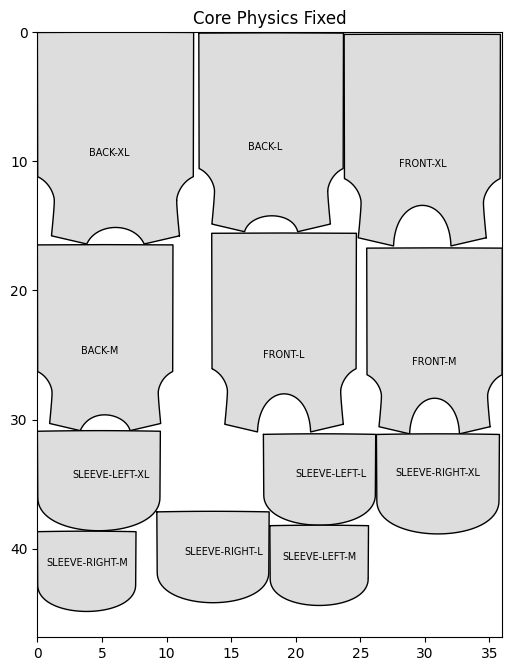


KPIs:
layer_length_in 44.848
used_area_in2 1271.603
total_area_in2 1614.519
empty_ratio 0.212


In [48]:
STRIP_WIDTH = 36
design_folder = "JK-123"

shape_items = process_design_folder(design_folder)

placed = core_pack(shape_items, STRIP_WIDTH)

render_marker(
    placed,
    strip_width=STRIP_WIDTH,
    title="Core Physics Fixed",
    save="JK-123/core_fixed.png"
)

kpi = evaluate_kpis(placed, STRIP_WIDTH)

print("\nKPIs:")
for k,v in kpi.items():
    print(k, round(v,3))
